# Single calcium recording CNMFe analysis using Inscopix API

The tutorial will explain the steps needed to extract calcium traces and cell maps from raw calcium recordings in isxd format using CNMFe algorithm.

## 0. install jupyter notebook nbextensions to view table of contents


To best view and navigate this template, installing [jupyter notebook nbextensions](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/nbextensions/toc2/README.html) to show table of contents (TOC) sidebar is highly recommended.

1. After activating isxenv (conda activate isxenv), paste the following two lines into the command line one at a time (more instructions see [this link](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/install.html)).

```
pip install https://github.com/ipython-contrib/jupyter_contrib_nbextensions/tarball/master

jupyter contrib nbextension install --user
```

2. After the installation completes and "jupyter notebook" program is initiated (by typing "jupyter notebook" inside isxenv), a new nbextensions tab will appear to the right of the Files tab. Users can enable TOC within the nbextensions tab and toggle the TOC button on and off from the tool bar.


3. ExecuteTime is also recommended to be turned on in the nbextensions tab to view the execution time for each cell (or use %%time function instead in selective cells)

## 1. prepare files

### 1.1 import python libraries

In [88]:
import isx  # to work with API
import numpy as np  # to manipulate matrix
import numpy.matlib  # to manipulate matrix
import pandas as pd  # data analysis library
import matplotlib.pyplot as plt  # data visualization
import matplotlib # for coloring cells differently
from matplotlib.pyplot import cm # for coloring cells differently

from scipy import stats  # calculate zscore
import os  # operating system
from pathlib import Path  # to work with dir
import tifffile as tiff  # to read tiff files
import shutil  # to move files

import warnings
# to suppress warnings from the output window
warnings.filterwarnings("ignore")
# to render the figures inside the current notebook
%matplotlib inline

### 1.2 set current working folder

### Users can download the longitudinal dataset from [Inscopix website](https://support.inscopix.com/support/products/data-processing-software/inscopix-data-processing-v131)

### **USER INPUT REQUIRED (1 of 5)**

In [4]:
###############################################################################
#--------USERS SPECIFY AN INPUT FOLDER WHERE THEY STORE THE RECORDINGS--------#
###############################################################################

"""
1. modify the path to match user's own dir
2. in windows system, a copy/pasted path needs to be prefixed with r:
   r'C:\Path\to\folder' or use \\ structure such as 'C:\\Path\\to\\folder'
3. Path library is used to standardize path format
   and be cross-platform compatible
"""

# set current working folder; change 'D:\demo' to match your own folder
os.chdir(r'D:\demo_cnmfe')

output_dir = Path(os.getcwd())
print('Current working folder:', output_dir)

Current working folder: D:\demo_cnmfe


###  1.3 load a calcium recording and view the metadata

### **USER INPUT REQUIRED (2 of 5)**

In [5]:
###############################################################################
#-----------------USERS SPECIFY A RECORDING FILE to PROCESS-------------------#
###############################################################################

# change the file name 'demo.isxd' to match users' own recording name

raw_movie_file = 'demo.isxd'


### extract the metadata using a custom function

In [6]:
# retrieve total number of frames, the sampling rate and the image size

def get_metadata(isxd_movie):
    """
    print metadata from a .isxd file

    Parameters:
        single movie in .isxd format

    Returns:
        None

    """
    load_movie = isx.Movie.read(isxd_movie)
    total_frames = load_movie.timing.num_samples
    sampling_rate = 1.0/load_movie.timing.period.secs_float
    image_size = load_movie.spacing.num_pixels
    metadata = ["The total number of frames: %d" % total_frames,
                "The sampling rate: %.2f Hz" % sampling_rate,
                "The image size in pixels: H %d x W %d" % image_size]
    print("Here are some metadata for "+isxd_movie+"\n")
    for each in metadata:
        print(each)


get_metadata(raw_movie_file)

Here are some metadata for demo.isxd

The total number of frames: 3999
The sampling rate: 5.56 Hz
The image size in pixels: H 396 x W 349


### 1.4 display a frame from the movie

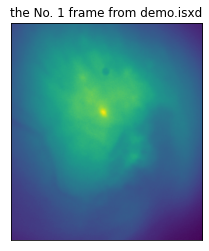

In [7]:
# load the first frame


def show_frame(isxd_movie, frame_number):
    """
    load frame and show the image in output window

    Parameters:
        isxd_movie: the source movie in .isxd format
        frame_number: which frame to be loaded

    Returns:
        frame: numpy matrix data from the specified frame

    """
    # get a frame from the movie
    frame = isx.Movie.read(isxd_movie).get_frame_data(frame_number)
    # show the frame
    plt.imshow(frame)
    plt.title("the No. %d frame from %s" % ((frame_number+1), isxd_movie))
    plt.xticks([])
    plt.yticks([])
    return frame


image = show_frame(raw_movie_file, 0)

In [8]:
isx.Movie.read(raw_movie_file)

## 2. Preprocess the movie: to reduce the file size and improve the processing speed

### **USER INPUT REQUIRED (3 of 5)**

Preprocessing, please wait...
Preprocessing completed. A new file has been generated.


Before preprocessing:
Here are some metadata for demo.isxd

The total number of frames: 3999
The sampling rate: 5.56 Hz
The image size in pixels: H 396 x W 349

After preprocessing:
Here are some metadata for prepro.isxd

The total number of frames: 3999
The sampling rate: 5.56 Hz
The image size in pixels: H 198 x W 174


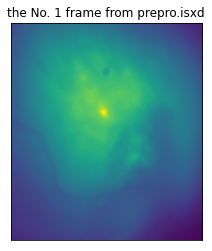

In [9]:
###############################################################################
#---PLEASE USE A PROPER TEMPORAL DOWNSAMPLING FACTOR TO MATCH THE GCAMP TYPE--#
#----4X SPATIAL DOWNSAMPLING IS RECOMMENDED FOR LONG RECORDINGS OR CNMFE------#
#-----FOR PARAMETER TUNING, CROPPING AND TRIM MOVIE COULD SAVE TIME-----------#
###############################################################################

print('Preprocessing, please wait...')

pp_file = 'prepro.isxd'

# adjust the two parameter below to reduce file size
tp_downsampling = 1 # usually: 2 (for a 20 Hz recording)
sp_downsampling = 2 # usually: 4 (for full resolution/FOV video)

if not os.path.exists(pp_file):  # skip if file exists
    isx.preprocess(
        input_movie_files=raw_movie_file,
        output_movie_files=pp_file,
        temporal_downsample_factor=tp_downsampling,
        spatial_downsample_factor=sp_downsampling,
        crop_rect=None,
        fix_defective_pixels=True,
        trim_early_frames=True)
    print('Preprocessing completed. A new file has been generated.\n')
else:
    print(pp_file + " already exists, process skipped")

show_frame(pp_file, 0)
print("\nBefore preprocessing:")
get_metadata(raw_movie_file)
print("\nAfter preprocessing:")
get_metadata(pp_file)

## 3. Spatial bandpass filtering: to increase neuronal signal contrast

In [10]:
# %%time
print('Applying bandpass filter, please wait...')

# make new output file name
bp_file = 'bp_filter.isxd'

if not os.path.exists(bp_file):
    isx.spatial_filter(
        input_movie_files='prepro.isxd',
        output_movie_files=bp_file,
        low_cutoff=0.005,
        high_cutoff=0.5,
        retain_mean=False,
        # leave subtract_global_minimum setting as true
        # for correct dff display
        subtract_global_minimum=True)
    print('Bandpass filtering completed. A new file has been generated.')
else:
    print(bp_file + " already exists, process skipped\n")

Applying bandpass filter, please wait...
Bandpass filtering completed. A new file has been generated.


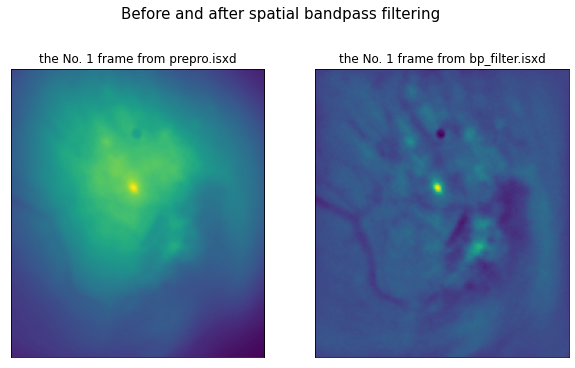

In [11]:
# compare image before and after bandpass filtering

fig = plt.figure(figsize=(10, 6))
fig.suptitle('Before and after spatial bandpass filtering', fontsize=15)

plt.subplot(121)
show_frame(pp_file, 0)  # load the first frame

plt.subplot(122)
show_frame(bp_file, 0)  # load the first frame
plt.show()

## 4. Motion correction: to stabilize the movie and correct rigid movement artifact
### 4.1 create reference image (mean projection) using temporal movie projection

Temporal projection completed.
A new file has been generated and will be used as a reference frame for motion correction


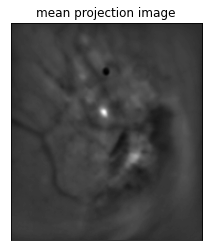

In [12]:
mc_ref = 'mc_mean_ref.isxd'

if not os.path.exists(mc_ref):
    isx.project_movie(
        input_movie_files=bp_file,
        output_image_file=mc_ref,
        stat_type='mean')  # types: 'mean', 'min', or 'max'
    print('Temporal projection completed.\n' +
          'A new file has been generated and will be used' +
          ' as a reference frame for motion correction')
else:
    print(mc_ref + " already exists, process skipped\n")

# show the mean projection image
sp_mean = isx.Image.read(mc_ref).get_data()
plt.imshow(sp_mean, 'gray')
plt.xticks([])
plt.yticks([])
plt.title('mean projection image')
plt.show()

### 4.2 motion correction

In [13]:
# %%time
print('Applying motion correction. Please wait...')

# make new output filename
# two optional csv files can be generated
mc_file = 'motion_corr.isxd'

# If you would like to align to a single frame instead, 
# remove line "refrence_file_name=mc_ref" and 
# indicate the frame number in "reference frame_index"

if not os.path.exists(mc_file):
    isx.motion_correct(
        input_movie_files=bp_file,
        output_movie_files=mc_file,
        max_translation=20,  # increase to correct larger motion artifact
        low_bandpass_cutoff=None,
        high_bandpass_cutoff=None,
        roi=None,
        reference_segment_index=0,
        reference_frame_index=0,
        # use the mean projection as a reference frame
        # for motion correction
        reference_file_name=mc_ref,
        global_registration_weight=1.0,
        # frame by frame x y shift
        output_translation_files='motion-corr-translation.csv',
        # store the motion corrected movie coordinates
        # top left width height values
        output_crop_rect_file='motion-corr-region.csv',
        preserve_input_dimensions = True)
    print('Motion correction completed. 3 new files have been generated.')
else:
    print(mc_file + " already exists, process skipped\n")

Applying motion correction. Please wait...
Motion correction completed. 3 new files have been generated.


## 5. Detecting cells
### 5.1: use CNMFe algorithm to segment cells

### **USER INPUT REQUIRED (4 of  5)**

In [18]:
%%time
###############################################################################
#---THE CNMFE ALGORITHM APPLIES TO THE CONCATENATED MOVIE FROM THE SERIES-----#
#--------EVERY RECORDING IN THIS SERIES WILL HAVE THE SAME CELLMAPS-----------#
#---------EVEN THOUGHT THE OUTPUT IS A CNMFE CELLSET SERIES-------------------#
###############################################################################
#----------PLEASE REFER TO IDPS MANUAL FOR PARAMETER SETTING TIPS-------------#
#----------ADJUST CELL_DIAMETER, MIN_PNR AND MIN_CORR VALUES AS NEEDED--------#
###############################################################################

cnmfe_file = 'cnmfe-cellset.isxd'
export_path = output_dir / 'cnmfe_tmp'

cell_diameter = 10; 
default_kernel_size= np.int(np.floor((cell_diameter - 1) / 4));

if not os.path.exists(cnmfe_file):
    if not os.path.exists(export_path):
        os.mkdir(export_path)
    isx.run_cnmfe(
        input_movie_files=mc_file,
        output_cell_set_files=cnmfe_file,
        output_dir=str(export_path),
        cell_diameter=cell_diameter,
        min_corr=0.7,
        min_pnr=10,
        bg_spatial_subsampling=2,
        ring_size_factor=1.4,
        gaussian_kernel_size= default_kernel_size,
        closing_kernel_size= default_kernel_size,
        merge_threshold=0.7,
        processing_mode='parallel_patches',
        num_threads=4,
        patch_size=80,
        patch_overlap=20,
        output_unit_type='df_over_noise')
    print("CNMFe analysis completed. A few temporary files have been " +
          "generated in cnmfe_tmp subfolder")
else:
    print(cnmfe_file + " already exists, process skipped\n")

CNMFe analysis completed. A few temporary files have been generated in cnmfe_tmp subfolder
Wall time: 2min 49s


### 5.3  deconvolve calcium traces

In [19]:
denoised_file = 'denoised-cellset.isxd'
spike_file = 'denoised-spikes.isxd'

isx.deconvolve_cellset(
    [cnmfe_file],
    [denoised_file],
    [spike_file],
    accepted_only=False,
    spike_snr_threshold=3.0,
    noise_range=(0.25, 0.5),
    noise_method='mean',
    first_order_ar=True,
    lags=5,
    fudge_factor=0.96,
    deconvolution_method='oasis')

### 5.4 detect events from the denoised traces using s.d threshold and decay time

In [20]:
# make new output filename
ed_file = 'cnmfe-cellset-events.isxd'

if not os.path.exists(ed_file):
    isx.event_detection(
        input_cell_set_files=denoised_file,
        output_event_set_files=ed_file,
        threshold=5,  # sigma threshold
        tau=0.2,  # default is 200ms for Gcamp6f
        event_time_ref='beginning',  # export other timing separately
        ignore_negative_transients=True,
        accepted_cells_only=False)
    print('Event detection completed. A new file has been generated.')
else:
    print(ed_file + " already exists, process skipped\n")

Event detection completed. A new file has been generated.


In [21]:
# make filenames to export events
event_csv = 'cnmfe-cellset-events.csv'
event_props_csv = 'cnmfe-cellset-events-props.csv'

if not os.path.exists(event_csv):
    isx.export_event_set_to_csv(
        input_event_set_files=ed_file,
        output_csv_file=event_csv,
        time_ref='start',
        output_props_file=event_props_csv)
    print('Event exporting completed. Two new files have been generated.')
else:
    print(event_csv + " already exists, process skipped\n")

Event exporting completed. Two new files have been generated.


### 5.5 automatically classify cell statuses as accepted or rejected

In [22]:
print('Applying auto classification. ' +
      'Please wait...\n')

# filter based on SNR, event rate and single component number

# make name for event filter
events_filters = [('SNR', '>', 3), ('Event Rate', '>', 0.0001), ('# Comps', '=', 1)]

isx.auto_accept_reject(input_cell_set_files=denoised_file,
                       input_event_set_files=ed_file,
                       filters=events_filters)
print('Auto classification completed. The denoised cnfme cellset has been updated.')

Applying auto classification. Please wait...

Auto classification completed. The denoised cnfme cellset has been updated.


### 5.6 export calcium traces and cell maps

In [23]:
def move_files(source, destination, type='.tiff'):
    """
    move files from source to destination, filtered by file type

    Parameters:
        source: path for source folder
        destination: path for destination folder
        type: file extension, by default only move tiff files

    Returns:
        None

    """
    if not os.path.exists(destination):
        os.mkdir(destination)  # make new subfolder
        # get file list from the source folder
        sourcefiles = os.listdir(source)
        for file in sourcefiles:
            if file.endswith(type):  # filter by file type
                shutil.move(os.path.join(source, file),
                            os.path.join(destination, file))
    else:
        print("Tiff folder already exists, process skipped\n")

In [24]:
# export a single csv file for all cell traces
# export multiple tiff files: one cell map for each file

# make filename for new output file
cnmfe_csv = 'cnmfe-denoised-cellset.csv'

if not os.path.exists(cnfme_csv):
    isx.export_cell_set_to_csv_tiff(
        input_cell_set_files=denoised_file,
        output_csv_file=cnmfe_csv,
        output_tiff_file='cnmfe-cell.tiff',
        time_ref='start',
        output_props_file='')
    print("Export completed. Tiff files are stored in the tiff subfolder")
else:
    print(cnfme_csv + " already exists, process skipped\n")

# move tiff files to a subfolder
move_files(output_dir, output_dir / 'cnmfe_tiff')

Export completed. Tiff files are stored in the tiff subfolder


### 5.6 show an example image (spatial footprint)

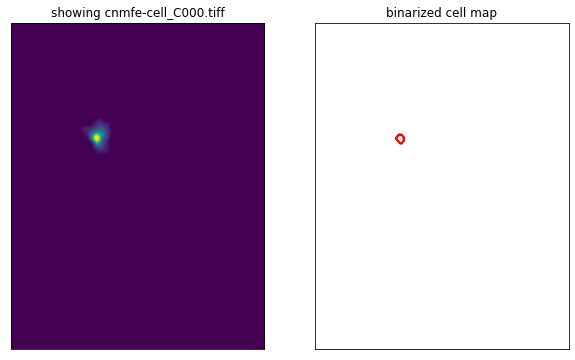

In [31]:
# load an image from the tiff subfolder
filename = 'cnmfe-cell_C000.tiff'
image_dir = output_dir / 'cnmfe_tiff' / filename
cell_image = tiff.imread(image_dir)

plt.figure(figsize=(10, 6))

plt.subplot(121)
plt.imshow(cell_image, aspect="auto")  # show the unthresholded image
plt.title('showing {}'.format(filename))
plt.xticks([])
plt.yticks([])

plt.subplot(122)
# show the cell map after threshold
cell_image = cell_image > (0.8 * np.max(cell_image))
plt.contour(cell_image, colors='red', linewidths=1, alpha=1)
plt.gca().invert_yaxis()
plt.title("binarized cell map")
plt.xticks([])
plt.yticks([])
plt.show()

### 5.7 display calcium traces from accepted cells and rejected cells

In [35]:
# load cell traces from the exported csv file

cellset = pd.read_csv(cnmfe_csv)

# check the first 10 rows of the table
cellset.head(10)

,,C000,C001,C002,C003,C004,C005,C006,C007,C008,...,C162,C163,C164,C165,C166,C167,C168,C169,C170,C171
0,Time(s)/Cell Status,accepted,accepted,accepted,accepted,accepted,accepted,accepted,accepted,rejected,...,accepted,accepted,accepted,accepted,accepted,accepted,accepted,accepted,accepted,accepted
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.179973,0,1.229391,0,0.327436,0,0,0,0.8295296,1.034384,...,0.680984,1.031729,1.283981,0,0,0.3652098,0,0,0,0
3,0.359946,0,4.034589,0,2.153728,0,0,0,0.6949297,2.087438,...,0.5731843,1.71103,1.036167,0.4033663,0,1.024737,0,4.768372e-07,0,0
4,0.539919,0,3.52546,1.065908,1.923169,-7.450581e-09,0,0,0.5821701,2.632814,...,0.4824494,1.685614,1.191329,0.5272188,0,0.8809585,0,4.768372e-07,0.1487013,0
5,0.719892,9.536743e-07,3.080579,0.9851562,3.088046,0,0,0,0.9595271,7.045682,...,0.4060777,1.444814,2.866619,0.460592,0,3.182303,0,0.857357,0.1267893,0
6,0.899865,4.768372e-07,8.314883,1.937172,2.757467,0,0,0,0.8038338,6.419804,...,0.3417956,2.188978,2.46077,1.583113,0,3.81967,0,1.887133,0.1081062,0
7,1.079838,9.536743e-07,8.261186,2.482251,2.462276,3.72529e-09,0,0,0.6734034,5.849523,...,0.4545264,1.940801,1.98583,1.383049,0,3.283741,0,1.723569,0.09217614,0
8,1.259811,9.536743e-07,7.218699,2.512216,4.249393,3.72529e-09,0,0,0.5641366,5.329902,...,1.639295,1.663546,2.811044,1.208268,0,2.823007,0.3555117,1.574183,0.07859343,-1.490116e-08
9,1.439784,4.768372e-07,6.307764,4.679735,3.912525,3.72529e-09,0,0,0.4725996,4.856439,...,5.766129,1.425898,5.127696,1.055575,0,2.426917,0.3032497,1.437743,0.06701225,-1.490116e-08


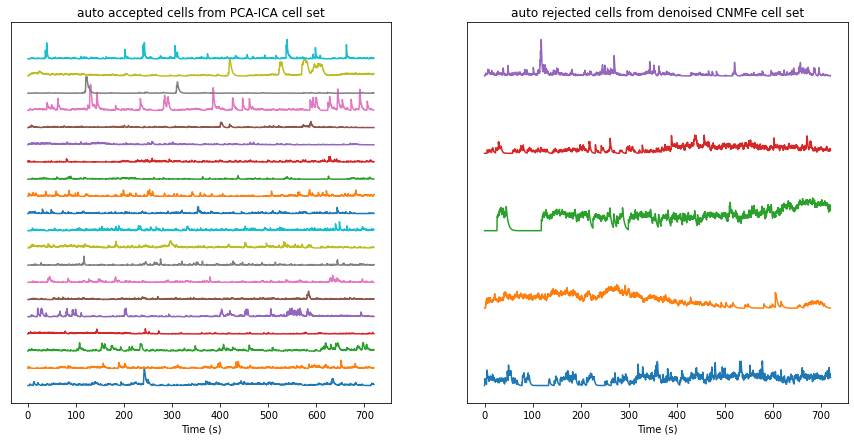

In [36]:
# Split cells into accept and reject groups
# scan first row for "accepted" or "rejected" cell label
# set boolean to 1 when find a match from the column index

# accepted cell columns set to 1
colfilter_acc = cellset.iloc[0, :].values == ' accepted'
# (a space is needed before the label 'accepted' or 'rejected')

# rejected cell columns set to 1
colfilter_rej = cellset.iloc[0, :].values == ' rejected'

# trace data start from the second row
# second to bottom row, filter by accepted cell columns
cells_acc = cellset.iloc[1:, colfilter_acc].astype('float')
# second to bottom row, filter by rejected cell columns
cells_rej = cellset.iloc[1:, colfilter_rej].astype('float')

# retrieve timestamps from the first column
timestamp = cellset.iloc[1:, 0].astype('float')

# plot the calcium traces and compare accepted cells with rejected cells
plt.figure(figsize=(15, 7))
plt.subplot(121)

offset = 0
for cell in range(min(20, cells_acc.shape[1])):
    plt.plot(timestamp, cells_acc.iloc[:, cell]-offset)
    offset -= 80  # separate the Y-axis for each trace
    plt.title('auto accepted cells from denoised CNMFe cell set')
    plt.xlabel('Time (s)')
    plt.yticks([])

plt.subplot(122)
offset = 0
# plot 20 example traces
for cell in range(min(20, cells_rej.shape[1])):
    plt.plot(timestamp, cells_rej.iloc[:, cell]-offset)
    offset -= 80
    plt.title('auto rejected cells from denoised CNMFe cell set')
    plt.xlabel('Time (s)')
    plt.yticks([])

### Alt 5.2 export calcium traces and cell maps for CNMFe dataset

In [24]:
# export csv and tiff file, make filename
# event detection, auto classification section from PCA-ICA
# can be reused for CNMFe cellset with slight modification of file name

cnmfe_csvfile = 'cnmfe-cellset.csv'

if not os.path.exists(cnmfe_csvfile):
    isx.export_cell_set_to_csv_tiff(
        input_cell_set_files=cnmfe_file,
        output_csv_file=cnmfe_csvfile,
        output_tiff_file='cnmfe-cellset.tiff',
        time_ref='start',
        output_props_file='cnmfe-cellset-props.csv')
    print("Export completed. Tiff files are stored in the tiff subfolder")
else:
    print(cnmfe_csvfile + " already exists, process skipped\n")

move_files(output_dir, output_dir / 'cnmfe_tiff')

Export completed. Tiff files are stored in the tiff subfolder


## 6. Data visualization after CNMFe cell detection

In [38]:
# define a function to extract calcium traces,
# cell maps and timestamps from a cellset .isxd file


def extract_cell(dataset, status_list=['accepted', 'rejected', 'undecided'], Zscore=False):
    """
    Extract calcium traces, cellmaps and timestamps
        and filtered by cell accepted/rejected/undecided status
    Parameters:
        dataset: pca-ica or cnmfe dataset
        status_list: status filter, default setting includes all categories
        Zscore: optional
                whether to convert traces to Zscore scale
                Default set to False to not convert
    Returns:
        cell_trace_all: cell by frame numpy matrix
                        trace series from all cells
                        Y axis scale is dependent on input cellset or Zscore setting
        cell_image_all: binarized cell maps from all cells
                        H pixels x W pixels x cell number.
        timestamps: timestamp extracted from the .isxd movie

    """

    cell_set = isx.CellSet.read(dataset)   # load the dataset
    num_cells = cell_set.num_cells  # retrieve cell number
    # retrieve the timestamps
    timestamps = [offset.secs_float for offset
                  in cell_set.timing.get_offsets_since_start()]
    total_frame_num = cell_set.timing.num_samples
    # initiate image holder and trace holder
    image_size = cell_set.get_cell_image_data(0).astype(np.float64)

    cell_image_all = np.empty(shape=(image_size.shape[0],
                                     image_size.shape[1], num_cells))
    cell_trace_all = np.empty(shape=(total_frame_num, num_cells))

    # set cell filter to label cells that match the input index list
    # initiation with false boolean
    id_filter = [False for i in range(num_cells)]

    # load cell images and traces into holder when the status matches
    for cell in range(num_cells):
        if (cell_set.get_cell_status(cell) in status_list):
            id_filter[cell] = True
        cell_image = cell_set.get_cell_image_data(cell).astype(np.float64)
        # threshold the cell image to get binarized cellmap
        cell_image = cell_image > (0.8 * np.max(cell_image))
        # append cell maps
        cell_image_all[:, :, cell] = cell_image

        # retrieve and append cell traces
        cell_trace = cell_set.get_cell_trace_data(cell)
        cell_trace_all[:, cell] = cell_trace

    # Optional: convert to Zscore
    if Zscore:
        cell_trace_all = stats.zscore(cell_trace_all)

    return (cell_trace_all[:, id_filter], cell_image_all[:, :, id_filter], timestamps)

### 6.1 Visualize all possible cells in the movie: 
2 ways : 
1) calculate dF/F movie and do a max projection

2) maximum projection of the motion corrected movie

In [ ]:
# %%time
print('Calculating dff. Please wait...')

# make new output filename
dff_file = 'dff.isxd'

if not os.path.exists(dff_file):
    isx.dff(input_movie_files=mc_file,
            output_movie_files=dff_file,
            f0_type='mean')
    print('A new df/f movie has been generated.')
else:
    print(dff_file + " already exists, process skipped\n")

# compute the maximal projection of the df/f0 movie
if os.path.exists('max_dff.isxd'):
    os.remove('max_dff.isxd')
isx.project_movie(
    input_movie_files='dff.isxd',
    output_image_file='max_dff.isxd', stat_type='max')
max_dff = isx.Image.read('max_dff.isxd').get_data()

# compute max projection of motion corrected movie 
if os.path.exists('max_proj.isxd'):
    os.remove('max_proj.isxd')

isx.project_movie(
    input_movie_files= mc_file,
    output_image_file='max_proj.isxd', stat_type='max')
max_proj = isx.Image.read('max_proj.isxd').get_data()

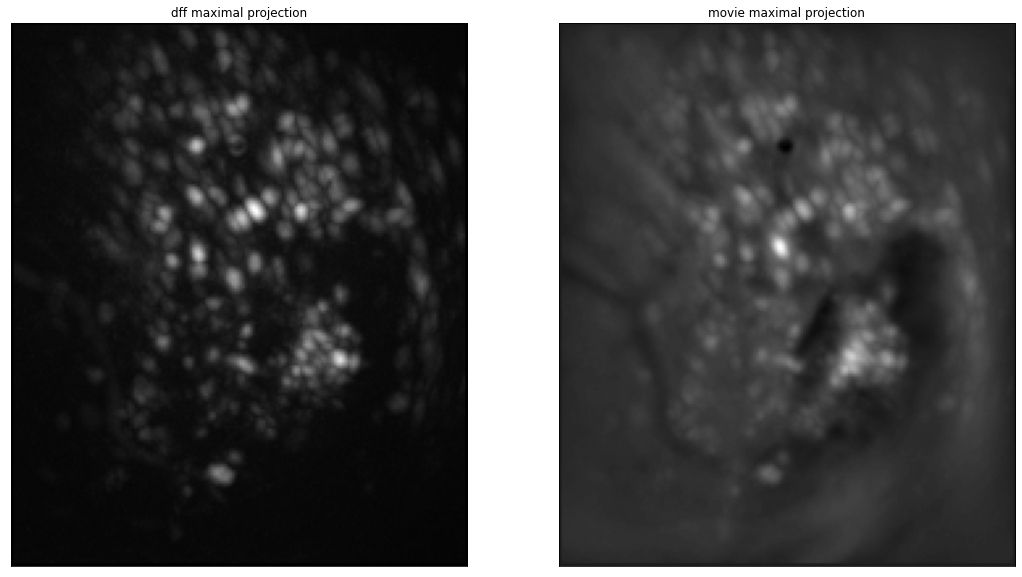

In [178]:
# plot max projection images

f, axs= plt.subplots(1,2, figsize=(18,10),sharey=True)
axs[0].imshow(max_dff, 'gray', aspect='auto')
axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_title('dff maximal projection')
axs[1].imshow(max_proj, 'gray',aspect='auto')
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].set_title('movie maximal projection')
plt.show()
    

### 6.1 plot cell map and z-scored calcium traces from CNMFe cell set (auto-accepted cells only)

The cell and frame number for the calcium trace matrix: 3999x167
The size of the cellmap matrix (pixelH x pixelW x cell number) is 198x174x167


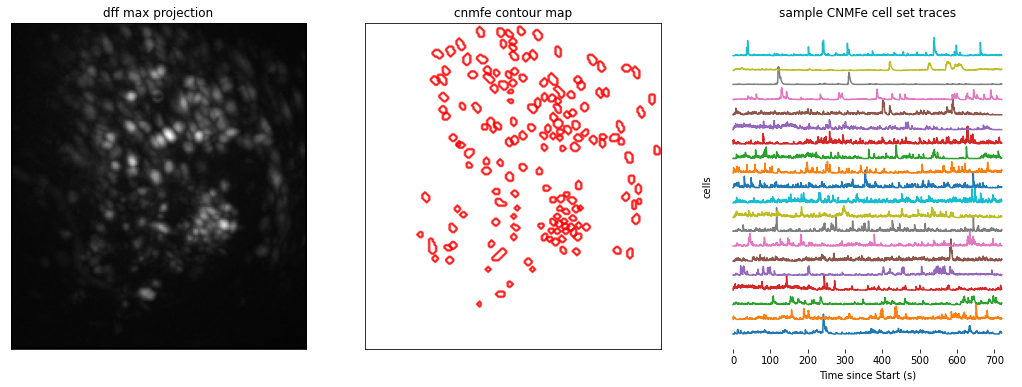

In [195]:
# retrieve the calcium traces and cellmap matrix from cnmfe cellset
# adjust the offset to increase or reduce spacing between traces

cnmfe_traces, cnmfe_cellmap, cnmfe_timestamps = extract_cell(
   denoised_file,  status_list=['accepted'], Zscore=True) # 'cnmfe-cellset.isxd')
print("The cell and frame number for the calcium trace matrix: \
%dx%d" % cnmfe_traces.shape)
print("The size of the cellmap matrix (pixelH x pixelW x cell number\
) is %dx%dx%d" % cnmfe_cellmap.shape)

# plot dff max projection and cnmfe contour map side by side
plt.figure(figsize=(18, 6))

# show dff movie max projection
plt.subplot(131)
plt.imshow(max_dff, 'gray', aspect="auto")
plt.xticks([])
plt.yticks([])
plt.title('dff max projection')

# get contour image from each cell
plt.subplot(132)
for i in range(1, cnmfe_cellmap.shape[2]):
    plt.contour(cnmfe_cellmap[:, :, i], colors='red', alpha=0.3)
plt.xticks([])
plt.yticks([])
plt.gca().invert_yaxis()
plt.title('cnmfe contour map')

# plot sample traces
plt.subplot(133, frameon=False)
offset = 0
for cell in range(20):
    plt.plot(cnmfe_timestamps, cnmfe_traces[:, cell]-offset)
    offset -= 10  # separate the Yaxis for each trace
plt.yticks([])    
plt.xlabel('Time since Start (s)')
plt.ylabel('cells')
plt.title('sample CNMFe cell set traces')
plt.show()

### **USER INPUT REQUIRED (5 of  5)**

### 6.2 Plot select cells where each cell trace and cell contour are the same color

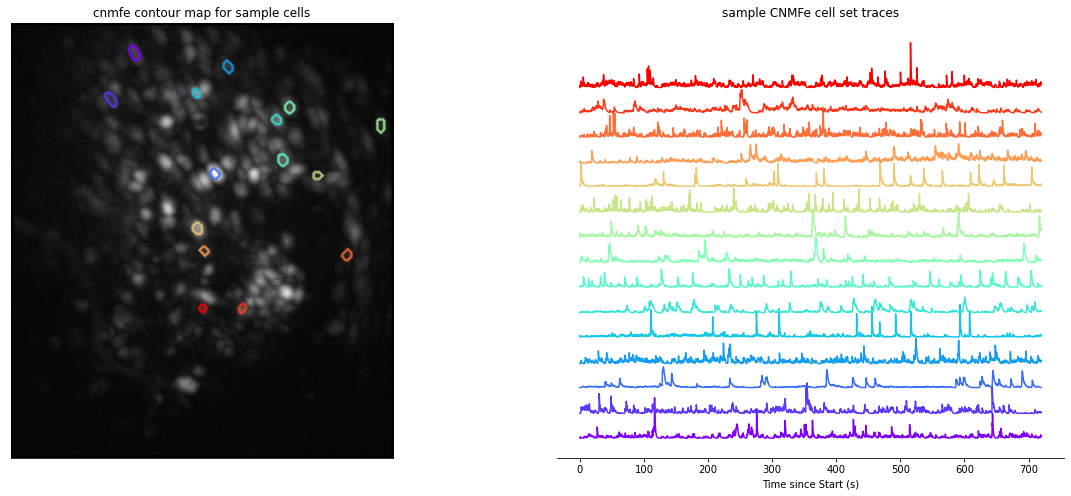

In [197]:
# Here I'm picking random cells, but if there are cells which you like and would like to showcase
# then sent cell_indices to those indices

#n selected cell indices
# picking n random cells
n = 15;
rng = np.random.default_rng(123456)
cell_indices = np.unique(rng.integers(low=0, high=cnmfe_traces.shape[1], size=n)) # note that actual number of cells can be less than n , because random can repeat indicies


# picking n colors and making a dictionary
color_dict = {}
color = iter(cm.rainbow(np.linspace(0, 1, n)))
for i in cell_indices :
   color_dict[i] = next(color)
   


# plot the cell contours and the traces
f, axs = plt.subplots(1,2, figsize=(20,8)) # initialize subplot
offset = 0 # for plotting traces

# first subplot: max_dff to overlay cell contours
axs[0].imshow(max_dff, 'gray')
# plot each cell
for i in cell_indices:
    # plot contour
    axs[0].contour(cnmfe_cellmap[:, :, i], alpha=0.3, colors=matplotlib.colors.to_hex(color_dict[i]))
    # plot trace
    axs[1].plot(cnmfe_timestamps, cnmfe_traces[:, i]-offset,c=color_dict[i])
    offset -= 10 # separate the y axis for each trace


axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_title('cnmfe contour map for sample cells')

axs[1].set_xlabel('Time since Start (s)')
axs[1].set_title('sample CNMFe cell set traces')
axs[1].set_yticks([])
axs[1].spines['right'].set_visible(False)
axs[1].spines['left'].set_visible(False)
axs[1].spines['top'].set_visible(False)
plt.show()


   

    

### 6.3 overlay the contour map from CNMFe cell sets onto max projection movie (not dff)

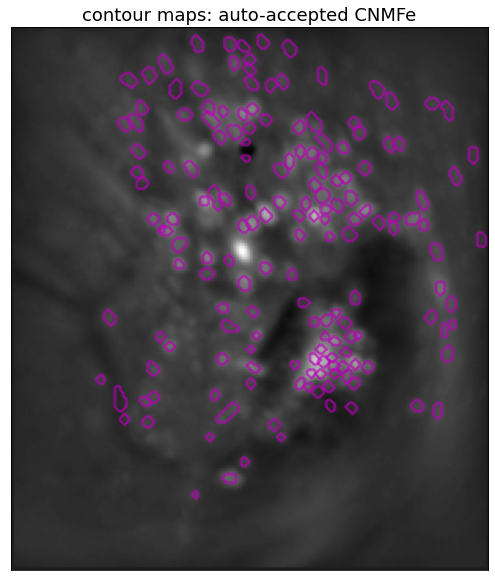

In [168]:

plt.figure(figsize=(25, 10))
plt.imshow(max_proj, 'gray')

# overlay the cellmaps from both cnmfe and pca-ica cellsets

for i in range(cnmfe_cellmap.shape[2]):
    plt.contour(cnmfe_cellmap[:, :, i], colors='m', linewidths=1, alpha=0.3)


plt.xticks([])
plt.yticks([])
plt.title('contour maps: auto-accepted CNMFe', fontsize=18)
plt.show()

In [28]:
# save the timestamp and cell traces into cnmfe_traces.csv file
# the first column is timestamp
# save the binarized cell map into a tiff file

np.savetxt('cnmfe_traces.csv',
           np.hstack((np.array(cnmfe_timestamps, np.float64).reshape(-1, 1),
                      cnmfe_traces)), delimiter=',')


# NOTE: If you only want to to write certain cells then select them from the cnmfe_cellmap matrix(3rd dim) and/or the cnfme_timestamps  before writing!
tiff.imwrite('cnmfe_cellmap.tiff',
             np.transpose(cnmfe_cellmap, (2, 1, 0)).astype('float32'))